# Постановка задачи


**Цель работы:** исследование и обработка данных для повышения их качества.

**Краткое описание:** в лабораторной работе приводится поэтапный план изучения и обработки намеренно не предобработанных данных. Необходимо выполнить все этапы плана и оценить результаты преобразований.

# Данные



В папке [Data/lab3](https://drive.google.com/drive/folders/1437z7m5Ut4WUJOhJg1oZz13dtBpxgFKs?usp=share_link) расположена таблица `monster_com_job_sample.com` с данными о вакансиях. Также эти данные с описанием и примерами обработки можно найти на [kaggle](https://www.kaggle.com/code/ankkur13/perfect-dataset-to-get-the-hands-dirty/data#).

##### **Формат данных**

```
country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
United States of America,US,"",No,jobs.monster.com,"TeamSoft is seeing an IT Support Specialist to join our client in Madison, WI. The ideal candidate must have at least 6 years of experience in the field. They need to be familiar with a variety of the field's concepts, practices, and procedures as this position relies on extensive experience and judgment to plan and accomplish goals. Required Skills:вАҐ Call tracking softwareвАҐ Phone based technical supportвАҐ Problem documentation and communicationвАҐ Remote Desktop Management ToolsвАҐ Respond to customer requestsвАҐ General understanding of LANDeskвАҐ Microsoft Office 2007 SuiteFind out why TeamSoft is the Madison area's technology leader with over 200 IT consultants. Owned, operated, and managed by IT consultants, TeamSoft is the clear choice for your career. Join the TeamSoft family today!Did you know?вАҐ TeamSoft offers salaried options for many positions that include 5 weeks PTO and great benefits!вАҐ TeamSoft has been in business since 1996вАҐ TeamSoft's owners are local IT professionals who possess a wealth of experience in application development, business analysis, and project managementвАҐ TeamSoft's Recruiters are knowledgeable, friendly, and ready to help you make your next great career moveвАҐ TeamSoft offers a full benefits suite to all of our W2 consultants, including a 401k plan with a 100% vested 4% dollar for dollar matchвАҐ Our targeted selection process is designed to get to know your strengths and career interests and provide you with the best chance for success in your new positionвАҐ Our longest running consultant has been with us for 16 yearsвАҐ Consultants can participate in our charitable giving committee. To date, TeamSoft's charitable giving committee has donated over $100,000!TeamSoft is owned by local IT professionals. Our team also has deep experience with IT staffing. Our clients understand this and rely on our expertise. That is why TeamSoft is the Madison Area's largest privately owned IT consulting firm, with more than 200 current consultants! With over 50 active clients, TeamSoft will give you the greatest exposure to the widest range of IT careers.Our owners possess a combined 60+ years of IT consulting experience. Our recruiting and Account Management staff are very well-versed in our client markets. We get you. We know you. We know what you do every day. And we know what you deal with on the job.You take your career seriously and so do we. At TeamSoft you are not just a resume or number. Our goal is to create long-term partnerships with each of our consultants, and according to feedback from many of them, we are very good at this. Click HERE to see what our consultants have to say about working with TeamSoft.TeamSoft -- Promote yourself!TeamSoft is an equal employment opportunity employer functioning under an Affirmative Action Plan.",IT Support Technician Job in Madison,Full Time Employee,"Madison, WI 53702","",http://jobview.monster.com/it-support-technician-job-madison-wi-us-167855963.aspx?mescoid=1500134001001&jobPosition=20,"",IT/Software Development,11d599f229a80023d2f40e7c52cd941e
United States of America,US,"",No,jobs.monster.com,"The Wisconsin State Journal is seeking a flexible and motivated reporter/editor to lead its three-person business desk. WeвАЩre looking for an experienced journalist able to spot trends, be a watchdog and reflect the Madison areaвАЩs vibrant entrepreneurial community. This is a hybrid reporting and editing position that calls for a fleet-footed, multimedia storyteller able to maximize the newspaperвАЩs online presentation while also editing two sections a week. Candidates must have strong news judgment, be well versed in business news and trends and be able to quickly prioritize coverage.At least five yearsвАЩ experience reporting or editing for digital and print platforms desired. To be considered for the position, applicants must apply online.¬†As part of your online application, please attach five samples of your work or links to five recent stories.Wisconsin State Journal, 1901 Fish Hatchery Road, Madison, WI 53713Affirmative Action/Equal Opportunity Employer/Pre-employment drug testing appliesPI94338362Apply Here",Business Reporter/Editor Job in Madison,Full Time,"Madison, WI 53708",Printing and Publishing,http://jobview.monster.com/business-reporter-editor-job-madison-wi-us-167830105.aspx?mescoid=2700437001001&jobPosition=7,"","",e4cbb126dabf22159aff90223243ff2a
...
```

##### **Описание полей**
 - ```country``` — наименование страны;
 - ```country_code``` — код страны;
 - ```date_added``` — дата размещения вакансии;
 - ```has_expired``` — актуальность вакансии;
 - ```job_board``` — агрегатор вакансий, с которого собраны данные;
 - ```job_description``` — описание вакансии;
 - ```job_title``` — наименование должности;
 - ```job_type``` — вид занятости;
 - ```location``` — метоположение организации;
 - ```organization``` — наименование организации;
 - ```page_url``` — ссылка на страницу с вакансией;
 - ```salary``` — заработная плата;
 - ```sector``` — сфера деятельности;
 - ```uniq_id``` — уникальный идентификатор записи о вакансии.

# Понимание данных

In [1]:
import re
import subprocess, sys
import numpy as np
import pandas as pd
try:
    import missingno as msno
except ImportError:  # в Colab этого модуля по умолчанию нет
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "missingno"])
    import missingno as msno
from matplotlib import pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_columns", 30)

В датасете есть несколько столбцов, в каждой ячейке которых записано одно и то же значение. Есть столбцы, в которых формат записи значений не стандартизирован. А есть такие, где указана информация, не соответствующая названию столбца.

**Первый этап изучения данных** – понять, какие основные проблемы предстоит решить для каждого из столбцов. Для этого загрузите датасет и выведите случайные несколько строк из него. Постарайтесь понять, что из себя представляют данные в столбцах.

In [2]:
import os

FILE = "monster_com_job_sample.csv"
if not os.path.exists(FILE):
    # Colab: выберите файл monster_com_job_sample.csv в открывшемся окне загрузки
    from google.colab import files
    files.upload()

df = pd.read_csv(FILE)
print("Размер датасета (строк, столбцов):", df.shape)
df.info()
df.sample(5, random_state=42)

Размер датасета (строк, столбцов): (22000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 22000 entries, 0 to 21999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   country          22000 non-null  str  
 1   country_code     22000 non-null  str  
 2   date_added       122 non-null    str  
 3   has_expired      22000 non-null  str  
 4   job_board        22000 non-null  str  
 5   job_description  22000 non-null  str  
 6   job_title        22000 non-null  str  
 7   job_type         20372 non-null  str  
 8   location         22000 non-null  str  
 9   organization     15133 non-null  str  
 10  page_url         22000 non-null  str  
 11  salary           3446 non-null   str  
 12  sector           16806 non-null  str  
 13  uniq_id          22000 non-null  str  
dtypes: str(14)
memory usage: 2.3 MB


,country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
13035,United States of America,US,NaN,No,jobs.monster.com,The QC Lead position requires an understanding of food science and...,Quality Control Lead Job in Santa Cruz,Full Time,"Santa Cruz, CA 95060",Manufacturing - Other,http://jobview.monster.com/Quality-Control-Lead-Job-Santa-Cruz-CA-...,NaN,Experienced (Non-Manager),c44af81ceb38d2b6fe00baf15d0dffe6
3115,United States of America,US,NaN,No,jobs.monster.com,JOB DESCRIPTION DEPARTMEN...,Case Manager Job in Sunset Point,Full Time Employee,"Sunset Point, FL 33765",Healthcare Services,http://jobview.monster.com/Case-Manager-Job-Sunset-Point-FL-US-166...,NaN,Medical/Health,217600308ffc96a1a81eb8afba5ee522
8732,United States of America,US,NaN,No,jobs.monster.com,POSITION PURPOSE The Senior Manager Foundation PR will be responsi...,Sr Manager,Full Time,"Atlanta, GA 30301",Retail,http://jobview.monster.com/sr-manager-foundation-pr-job-atlanta-ga...,NaN,Manager (Manager/Supervisor of Staff),ef7db9ba10dd8bf7754ecf6ddd09a5aa
7591,United States of America,US,NaN,No,jobs.monster.com,GroundskeeperWest Knox Apart need a F/T Groundskeeper. Duties - cl...,Groundskeeper Job in Knoxville,Full Time,"Knoxville, TN 37923",NaN,http://jobview.monster.com/Groundskeeper-Job-Knoxville-TN-US-16698...,NaN,NaN,cd3adb94fc647ca5ea3af731dc1da065
221,United States of America,US,NaN,No,jobs.monster.com,"Combined Insurance is seeking Sales Agents to join our fast-paced,...",Sales Agent Job in Knoxville,Full Time,"Knoxville, TN",Insurance,http://jobview.monster.com/Sales-Agent-Job-Knoxville-TN-US-1662799...,NaN,NaN,ec59e3f419b851259632b757183d7365


**Задание**

Составьте таблицу, в которой будет содержаться название столбца, тип данных в нем и краткое описание проблем, которые вы заметили при первом взгляде на данные.


Название столбца | Тип данных | Проблемы
--- | --- | ---
```country``` | str (категориальный) | Во всех 22 000 строках одно значение — `United States of America`; информации для анализа нет, дублирует `country_code`.
```country_code``` | str (категориальный) | Всегда `US`; дублирует `country`.
```date_added``` | str (должна быть дата) | 99,45% пропусков (заполнено только 122 ячейки из 22 000); даты записаны строкой в формате `M/D/YYYY` без ведущих нулей — нужно приводить к `datetime`.
```has_expired``` | str (Yes/No, булев) | Всегда `No` — константа, для анализа бесполезна.
```job_board``` | str (категориальный) | Всегда `jobs.monster.com` — константа (один источник данных).
```job_description``` | str (длинный текст) | Мусор в тексте: неразрывные пробелы `\xa0` (в ~58% описаний), фрагменты CSS/JS в фигурных скобках, слова слеплены без пробела на стыке фраз и пунктов списка; текст из этого столбца «протекает» в другие столбцы (`location`, `job_title`, `salary`, `sector`).
```job_title``` | str (текст) | В 85,7% строк в конце добавлено `Job in <город>`; в 794 строках — служебный мусор страницы (`Monster.com`, `MONS_LOG_VARS`); 12 названий должностей и служебных слов (например, `Job Details`) встречаются и в `job_title`, и в `location`.
```job_type``` | str (категориальный, составной) | 39 разных написаний (регистр, разделители `,` / ` , ` / `/` / `/ >`, лишние пробелы, префикс `Job Type`); в одной ячейке смешаны «полнота» и «тип» занятости; 1 628 пропусков (7,4%); встречаются значения вне описания (`Seasonal`, `Temporary/Contract/Project`, `Exempt`).
```location``` | str (составной) | 9 разных форматов записи (город, штат, индекс — в разных комбинациях и с разными разделителями); в 1 400 строк вместо места записан длинный текст (в основном кусок описания вакансии), контактные данные, телефоны, «Multiple locations» и т. п.
```organization``` | str (категориальный) | 31,2% пропусков; по содержанию это не организация, а отрасль (`Healthcare Services`, `Retail`…); значение `All` в 1 158 строках; в 227 строк записан город (значение совпадает с `location`).
```page_url``` | str (URL) | Проблем с форматом нет, все значения уникальны; но в URL «зашиты» должность, город, штат и параметры `mescoid`/`jobPosition`, по которым можно найти повторы объявлений.
```salary``` | str (должна быть числовая) | 84,3% пропусков; числа записаны строкой с запятыми-разделителями; форматы разные (диапазон, `A+`, `Up to`, одно число), с `$` и без, период указан не всегда; после периода часто прилеплен текст (`/yearBonus, Benefits`); у 399 записей суммы нет вовсе (`DOE`, `Competitive`…).
```sector``` | str (категориальный) | 23,6% пропусков; в столбце смешаны сфера деятельности и уровень карьеры/образования (`Entry Level`, `Experienced (Non-Manager)`, `Student…`, `Career Level …`) — 6 846 строк; несколько категорий склеены без разделителя (`Computer/Network SecurityGeneral/Other: …`).
```uniq_id``` | str (хеш, идентификатор) | Все значения уникальны, но уникальность ключа не означает уникальность вакансии: одна и та же вакансия встречается под разными `uniq_id` (см. раздел «Дублирование данных»).


### Оценка пустых ячеек в датасете

Выясните, в каких столбцах, строках и в каком количестве отсутствуют данные:
1. С помощью модуля `pandas` составьте таблицу, где каждому названию столбца будет сопоставлено общее количество ячеек и количество пустых ячеек.
2. Подсчитайте количество строк датасета, в которых пустыми являются более 75% ячеек.
3. Визуализируйте число пропусков в датасете с помощью модуля, построив столбчатую диаграмму. Для удобства можно воспользоваться модулем `missingno`.


,всего ячеек,пустых ячеек,"пустых, %"
date_added,22000,21878,99.45
salary,22000,18554,84.34
organization,22000,6867,31.21
sector,22000,5194,23.61
job_type,22000,1628,7.40
country,22000,0,0.00
job_description,22000,0,0.00
job_board,22000,0,0.00
has_expired,22000,0,0.00
country_code,22000,0,0.00


Ячеек, состоящих только из пробелов: 3

Строк, где пусто более 75% ячеек: 0
Максимальная доля пустых ячеек в одной строке: 35.7%
      число строк
0.00            5
0.07         2022
0.14        10892
0.21         6751
0.29         1588
0.36          742


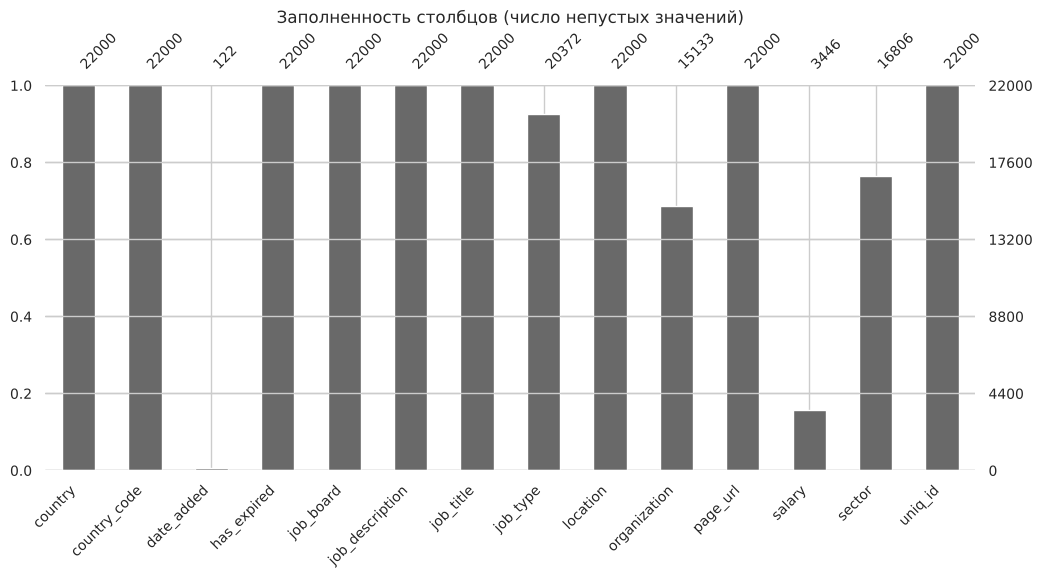

In [3]:
# 1. Таблица пропусков по столбцам
missing = pd.DataFrame({
    "всего ячеек": len(df),
    "пустых ячеек": df.isna().sum(),
})
missing["пустых, %"] = (missing["пустых ячеек"] / missing["всего ячеек"] * 100).round(2)
display(missing.sort_values("пустых ячеек", ascending=False))

# «Скрытые» пропуски: ячейки из одних пробелов
blank = df.apply(lambda c: c.astype("string").str.strip().eq("").sum())
print("Ячеек, состоящих только из пробелов:", int(blank.sum()))

# 2. Строки, где пусто больше 75% ячеек
empty_share = df.isna().mean(axis=1)
print("\nСтрок, где пусто более 75% ячеек:", int((empty_share > 0.75).sum()))
print("Максимальная доля пустых ячеек в одной строке: {:.1%}".format(empty_share.max()))
print(empty_share.round(2).value_counts().sort_index().rename("число строк").to_frame())

# 3. Визуализация числа пропусков
msno.bar(df, figsize=(12, 5), fontsize=10)
plt.title("Заполненность столбцов (число непустых значений)")
plt.show()

**Вывод по пропускам.**
- Пропуски сосредоточены в пяти столбцах: `date_added` (99,45% — 21 878 из 22 000), `salary` (84,34%), `organization` (31,21%), `sector` (23,61%) и `job_type` (7,40%). Остальные девять столбцов заполнены полностью. Ещё 3 ячейки состоят только из пробелов — это «скрытые» пропуски.
- Строк, где пусто более 75% ячеек, **нет**: максимум — 35,7% (5 из 14 столбцов). Причина в том, что четыре константных столбца и столбцы с текстом (`job_description`, `job_title`, `location`, `page_url`, `uniq_id`) заполнены всегда, поэтому критерий «75%» здесь ничего не отсеивает.
- `date_added` фактически непригоден для анализа; `salary` пригоден только для подвыборки (3 446 вакансий).

Проверьте, как изменится размер датасета, если принять решение удалить все строки, где есть пустые значения. Сделайте выводы.

In [4]:
print("Исходный размер:           ", df.shape)
print("После dropna() по всем:    ", df.dropna().shape)
print("После dropna() без date_added:", df.drop(columns="date_added").dropna().shape)

# Что останется, если убрать только строки с пропусками в «ключевых» столбцах
for col in ["job_type", "organization", "salary", "sector", "date_added"]:
    print(f"dropna(subset=['{col}']) -> {df.dropna(subset=[col]).shape[0]} строк")

Исходный размер:            (22000, 14)


После dropna() по всем:     (5, 14)
После dropna() без date_added: (1919, 13)
dropna(subset=['job_type']) -> 20372 строк
dropna(subset=['organization']) -> 15133 строк
dropna(subset=['salary']) -> 3446 строк
dropna(subset=['sector']) -> 16806 строк
dropna(subset=['date_added']) -> 122 строк


**Вывод.** Удалять все строки с пропусками нельзя: от 22 000 вакансий остаётся **5** (0,02%). Даже если убрать из рассмотрения `date_added`, остаётся 1 919 строк (8,7%). Значит, пропуски надо обрабатывать по столбцам: `date_added` исключить из анализа, `salary` оставить пустым там, где суммы нет (поле необязательное), `job_type` дозаполнить по правилу из задания 3, а `sector`/`organization` — использовать с оговоркой на пропуски.

### Первичная оценка данных в столбцах

Изучите данные в столбцах датасета, ответив на следующие вопросы:
1. Есть ли столбцы, в которых встречается всего одно значение? Как их можно использовать в анализе?
2. Есть ли такие значения, которые встречаются более чем в одном столбце?
3. Есть ли столбцы, данные в которых не соответствуют названию столбца?

In [5]:
# 1. Столбцы, в которых встречается всего одно значение
nun = df.nunique(dropna=False)
const_cols = nun[nun == 1].index.tolist()
print("Столбцы с одним значением:")
for c in const_cols:
    print(f"  {c:13s} -> {df[c].iloc[0]!r}")

# 2. Значения, которые встречаются более чем в одном столбце
skip = set(const_cols) | {"uniq_id", "page_url", "job_description"}   # константы, уникальные ключи и длинные тексты
check_cols = [c for c in df.columns if c not in skip]
vals = {c: set(df[c].dropna().unique()) for c in check_cols}
rows = []
for i, a in enumerate(check_cols):
    for b in check_cols[i + 1:]:
        common = vals[a] & vals[b]
        if common:
            rows.append({
                "столбец A": a, "столбец B": b,
                "общих значений": len(common),
                "строк в A": int(df[a].isin(common).sum()),
                "строк в B": int(df[b].isin(common).sum()),
                "примеры": sorted(common)[:3],
            })
display(pd.DataFrame(rows))

# 3. Столбцы, данные в которых не соответствуют названию
CAREER_LEVELS = ["Entry Level", "Experienced (Non-Manager)", "Manager (Manager/Supervisor of Staff)",
                 "Executive (SVP, VP, Department Head, etc)", "Senior Executive (President, CFO, etc)"]
is_level = df["sector"].isin(CAREER_LEVELS) | df["sector"].str.startswith("Student", na=False) \
           | df["sector"].str.startswith(("Career Level", "Education Level"), na=False)
glued = df["sector"].str.contains(r"[a-z][A-Z][a-z]+/|[a-z]General/Other", na=False)

loc_long = df["location"].str.len() > 60
loc_in_descr = [v[:40] in d for v, d in zip(df.loc[loc_long, "location"], df.loc[loc_long, "job_description"])]

report = pd.DataFrame([
    ("sector", "уровень карьеры/образования вместо сферы деятельности", int(is_level.sum())),
    ("sector", "несколько категорий склеены без разделителя", int(glued.sum())),
    ("organization", "значение «All»", int((df["organization"] == "All").sum())),
    ("organization", "значение = местоположение (есть и в location)", int(df["organization"].isin(vals["location"]).sum())),
    ("location", "длинный текст (>60 симв.) вместо места", int(loc_long.sum())),
    ("location", "…из них начало текста есть в job_description", int(sum(loc_in_descr))),
    ("job_title", "служебный мусор страницы (Monster.com / MONS_LOG_VARS)", int(df["job_title"].str.contains("Monster.com|MONS_LOG_VARS", na=False).sum())),
    ("job_title", "в конце добавлено «Job in <город>»", int(df["job_title"].str.contains(r" Job in ", na=False).sum())),
    ("salary", "нет суммы (DOE, Competitive и т.п.)", int((df["salary"].notna() & ~df["salary"].str.contains(r"\d", na=False)).sum())),
], columns=["столбец", "что не так", "число строк"])
display(report)

print("Топ-10 значений organization:")
display(df["organization"].value_counts().head(10).to_frame("число строк"))

Столбцы с одним значением:
  country       -> 'United States of America'
  country_code  -> 'US'
  has_expired   -> 'No'
  job_board     -> 'jobs.monster.com'


,столбец A,столбец B,общих значений,строк в A,строк в B,примеры
0,job_title,location,12,29,24,"[Business Analyst, Field Service Technician, Job Details]"
1,job_type,location,1,6617,9,[Full Time Employee]
2,job_type,organization,1,6617,9,[Full Time Employee]
3,location,organization,126,4097,227,"[A & E Network, Albany, NY, Allentown, PA]"
4,organization,sector,2,1082,24,[Electrical/Electronics EngineeringIndustrial/Manufacturing Engine...


,столбец,что не так,число строк
0,sector,уровень карьеры/образования вместо сферы деятельности,6846
1,sector,несколько категорий склеены без разделителя,68
2,organization,значение «All»,1158
3,organization,значение = местоположение (есть и в location),227
4,location,длинный текст (>60 симв.) вместо места,1400
5,location,…из них начало текста есть в job_description,1215
6,job_title,служебный мусор страницы (Monster.com / MONS_LOG_VARS),794
7,job_title,в конце добавлено «Job in <город>»,18855
8,salary,"нет суммы (DOE, Competitive и т.п.)",361


Топ-10 значений organization:


,число строк
organization,
Healthcare Services,1919
All,1158
Retail,1081
Other/Not Classified,1048
Manufacturing - Other,885
Computer/IT Services,822
Legal Services,466
Business Services - Other,410
Restaurant/Food Services,384


**Ответы на вопросы.**

1. **Столбцы с одним значением:** `country` (`United States of America`), `country_code` (`US`), `has_expired` (`No`), `job_board` (`jobs.monster.com`). Для анализа и моделей они бесполезны — дисперсия нулевая, их можно удалить. Использовать можно как «паспорт» набора данных (все вакансии из США, с одного агрегатора, актуальные на момент выгрузки) и как проверку при объединении с другими источниками.
2. **Значения, встречающиеся более чем в одном столбце:** `location` ∩ `organization` — 126 общих значений (в `organization` в 227 строк записан город, например `Irving, TX`); `job_type` ∩ `location` и `job_type` ∩ `organization` — `Full Time Employee` (по 9 строк: значение «съехало» в чужой столбец); `organization` ∩ `sector` — 2 значения (например, `Retail`: это и отрасль в `organization`, и категория в `sector`); `job_title` ∩ `location` — 12 значений (должности и служебные слова вроде `Project Manager`, `Job Details` попали в `location`, 24 строки).
3. **Столбцы, данные в которых не соответствуют названию:** `sector` (6 846 строк содержат уровень карьеры/образования, а не сферу), `organization` (содержит отрасли и значение `All`, а не названия компаний), `location` (1 400 строк — длинный текст, 1 215 из них начинаются с фрагмента `job_description`), `job_title` (служебный мусор страницы и добавка `Job in <город>`).

### Дублирование данных

Для поиска дублирующихся строк выполните следующие действия:
1. В таблице есть столбец `uniq_id`, значения которого, как сказано в описании данных, являются уникальными идентификаторами записей. Проверьте, действительно ли в этом столбце все значения различны.
2. Проверьте, есть ли в таблице другие столбцы, значения которых в каждой строке различны.
3. Если игнорировать столбцы, где все значения различны, найдутся ли такие строки, для которых значения по всем остальным столбцам будут совпадать?

Оцените результаты поиска дубликатов.

In [6]:
# 1. Уникален ли uniq_id?
print("uniq_id уникален:", df["uniq_id"].is_unique, "| повторов:", df["uniq_id"].duplicated().sum())

# 2. Столбцы, у которых все значения различны
all_diff = [c for c in df.columns if df[c].nunique(dropna=False) == len(df)]
print("Столбцы со всеми различными значениями:", all_diff)

# 3. Дубликаты по всем остальным столбцам
rest = [c for c in df.columns if c not in all_diff]
dup_all = df[df.duplicated(subset=rest, keep=False)].copy()
print(f"\nСтрок, входящих в группы-дубликаты: {len(dup_all)}")
print(f"Лишних строк (если оставить по одной в группе): {df.duplicated(subset=rest).sum()}")

dup_all["group"] = dup_all.groupby(rest, dropna=False).ngroup()
sizes = dup_all.groupby("group").size()
print("Групп дубликатов:", sizes.size)
print("Размеры групп:\n", sizes.value_counts().sort_index().rename("число групп").to_frame())

# чем отличаются записи внутри группы: смотрим page_url
dup_all["url_base"] = dup_all["page_url"].str.replace(r"[&?]jobPosition=\d+", "", regex=True)
print("\nГрупп, где page_url отличается ТОЛЬКО параметром jobPosition:",
      int((dup_all.groupby("group")["url_base"].nunique() == 1).sum()), "из", sizes.size)
display(dup_all.sort_values("group")[["group", "job_title", "location", "page_url"]].head(6))

uniq_id уникален: True | повторов: 0


Столбцы со всеми различными значениями: ['page_url', 'uniq_id']



Строк, входящих в группы-дубликаты: 2078


Лишних строк (если оставить по одной в группе): 1168
Групп дубликатов: 910
Размеры групп:
     число групп
2           809
3            61
4            16
5             8
6             5
7             2
9             1
10            1
11            2
13            2
16            1
22            1
24            1

Групп, где page_url отличается ТОЛЬКО параметром jobPosition: 469 из 910


,group,job_title,location,page_url
15246,0,Field Laborer (No Experience Required) Job in Cannon Falls,"Cannon Falls, MN",http://jobview.monster.com/field-laborer-no-experience-required-jo...
15562,0,Field Laborer (No Experience Required) Job in Cannon Falls,"Cannon Falls, MN",http://jobview.monster.com/field-laborer-no-experience-required-jo...
4720,1,Corporate Fit For Duty Program Manager Job in Norwell,"Norwell, MA",http://jobview.monster.com/corporate-fit-for-duty-program-manager-...
10527,1,Corporate Fit For Duty Program Manager Job in Norwell,"Norwell, MA",http://jobview.monster.com/corporate-fit-for-duty-program-manager-...
10645,2,Resource Management Program Analyst - Senior Job in Alexandria,"Alexandria, VA",http://jobview.monster.com/resource-management-program-analyst-sen...
4718,2,Resource Management Program Analyst - Senior Job in Alexandria,"Alexandria, VA",http://jobview.monster.com/resource-management-program-analyst-sen...


**Оценка дубликатов.**
- `uniq_id` — действительно уникален (повторов нет). Все значения различны также в `page_url`.
- Если не учитывать эти два столбца, совпадающими по всем остальным оказываются **2 078 строк**, образующих **910 групп**; «лишних» строк — **1 168 (5,3% датасета)**. В большинстве групп по 2 записи (809), но есть группы до 24 повторов.
- В 469 группах `page_url` отличается только параметром `jobPosition` (позиция объявления в выдаче) — это одно и то же объявление, которое парсер собрал несколько раз; в остальных группах URL отличаются и другими частями, но заголовок, описание, место, отрасль и т. д. совпадают целиком.
- Вывод: `uniq_id` не гарантирует уникальность вакансии. Перед подсчётом статистик по вакансиям (например, средних зарплат) такие повторы стоит удалить (`df.drop_duplicates(subset=rest)`); в этой работе исходные строки сохранены, чтобы не терять данные для следующих заданий.

# Практические задания

В этом разделе необходимо обработать значения в трех столбцах датасета: `location`, `salary` и `job_type`. Цель обработки – стандартизировать данные в каждом из столбцов так, чтобы их можно было анализировать.

### Задание 1

В задании 1 необходимо провести обработку столбца `location`.

#### Задание 1.1

В столбце `location` представлена информация о местоположении организации, в которой открыта вакансия. Каждое значение столбца `location` содержит информацию о городе, коде штата и почтовом индексе.

Однако не в каждой строке есть все три характеристики местоположения, а также могут встречаться разные комбинации из них, записанные в виде строки в произвольном порядке и с разными разделителями.

Например, может быть указан только код штата, только название города или только индекс. Могут быть указаны любые две характеристики из трех.

**Формулировка задания:**
1. Определите, какие форматы встречаются.
2. Напишите одно или несколько регулярных выражений для поиска выявленных форматов.
3. Визуализируйте количество найденных форматов на столбчатой или круговой диаграмме. Также покажите на ней количество строк, в которых формат определить не удалось. Какие форматы встречаются чаще всего?

Ознакомиться с теоретическим материалом по работе с регулярными выражениями можно [по ссылке](https://colab.research.google.com/drive/1eFHdmt9OROLEDJRNc2wNmz0gpE1O3sKU?usp=sharing).

,число строк,доля
"Город, Штат Индекс",11373,0.5170
"Город, Штат",7171,0.3260
не определён,2518,0.1145
Город Индекс,326,0.0148
Только индекс,254,0.0115
Только штат,230,0.0105
ГородШтат (слитно),91,0.0041
Штат Индекс,21,0.0010
Город Штат,15,0.0007
Город Штат Индекс,1,0.0000


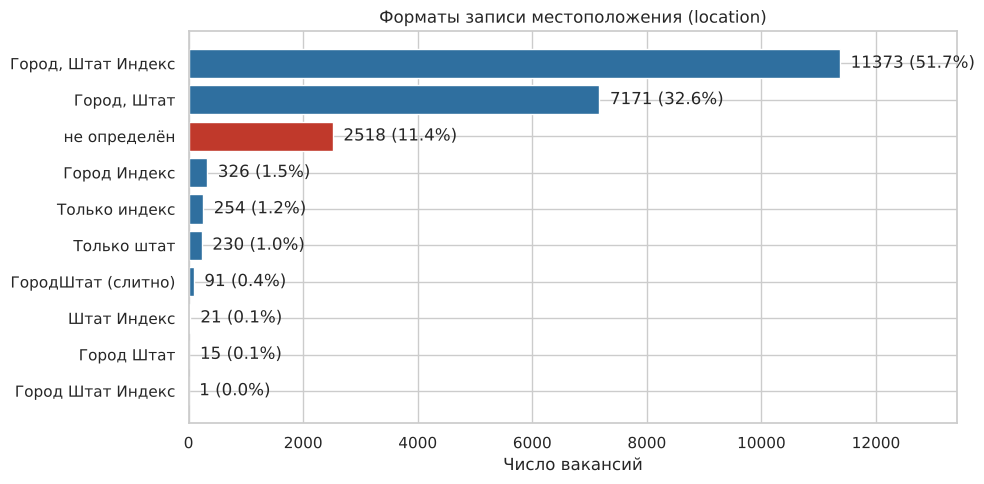

In [7]:
STATES = ("AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR "
          "PA RI SC SD TN TX UT VT VA WA WV WI WY DC PR GU VI").split()
STATE = "(?:" + "|".join(STATES) + ")"
CITY = r"[A-Za-z][A-Za-z.'\-]*(?:\s[A-Za-z.'\-]+)*"        # одно или несколько слов
ZIP = r"\d{5}(?:-\d{4})?"
UNKNOWN = "не определён"

# Порядок важен: сначала более полные форматы. Все выражения привязаны к началу и концу строки.
LOCATION_PATTERNS = {
    "Город, Штат Индекс":      rf"^(?P<city>{CITY})\s*,\s*(?P<state>{STATE})\s+(?P<zip>{ZIP})$",
    "Город, Штат":             rf"^(?P<city>{CITY})\s*,\s*(?P<state>{STATE})$",
    "Город Штат Индекс":       rf"^(?P<city>{CITY})\s+(?P<state>{STATE})\s+(?P<zip>{ZIP})$",
    "Город Штат":              rf"^(?P<city>{CITY})\s+(?P<state>{STATE})$",
    "ГородШтат (слитно)":      rf"^(?P<city>[A-Z][a-z]+(?:\s?[A-Z][a-z]+)*)(?P<state>{STATE})$",
    "Штат Индекс":             rf"^(?P<state>{STATE})\s+(?P<zip>{ZIP})$",
    "Город Индекс":            rf"^(?P<city>{CITY})\s+(?P<zip>{ZIP})$",
    "Только штат":             rf"^(?P<state>{STATE})$",
    "Только индекс":           rf"^(?P<zip>{ZIP})$",
}

# нормализуем пробелы: неразрывные, повторяющиеся, по краям
loc_clean = (df["location"].str.replace("\xa0", " ", regex=False)
                           .str.replace(r"\s+", " ", regex=True).str.strip())

loc_fmt = pd.Series(UNKNOWN, index=df.index)
found = []
for name, pat in LOCATION_PATTERNS.items():
    todo = loc_fmt.index[loc_fmt == UNKNOWN]
    ext = loc_clean.loc[todo].str.extract(pat)
    ext = ext[ext.notna().any(axis=1)]          # строки, где выражение сработало
    loc_fmt.loc[ext.index] = name
    found.append(ext)
loc_parts = pd.concat(found).reindex(df.index).reindex(columns=["city", "state", "zip"])

fmt_counts = loc_fmt.value_counts()
display(fmt_counts.rename("число строк").to_frame().assign(доля=lambda t: (t["число строк"] / len(df)).round(4)))

fig, ax = plt.subplots(figsize=(10, 5))
order = fmt_counts.index[::-1]
ax.barh(order, fmt_counts[order].values, color=["#c0392b" if i == UNKNOWN else "#2f6f9f" for i in order])
for y, v in enumerate(fmt_counts[order].values):
    ax.text(v, y, f"  {v} ({v / len(df):.1%})", va="center")
ax.set_xlim(0, fmt_counts.max() * 1.18)
ax.set_xlabel("Число вакансий")
ax.set_title("Форматы записи местоположения (location)")
plt.tight_layout()
plt.show()

**Вывод по заданию 1.1.** Найдено 9 форматов (9 регулярных выражений, применяются по очереди от более полных к менее полным). Чаще всего встречаются:
1. `Город, Штат Индекс` (например, `Madison, WI 53702`) — 11 373 строки (51,7%);
2. `Город, Штат` — 7 171 (32,6%).

Вместе это 84,3% датасета. Остальные форматы редки: `Город Индекс` (326), `Только индекс` (254), `Только штат` (230), `ГородШтат` слитно (91, например `DallasTX`), `Штат Индекс` (21), `Город Штат` (15), `Город Штат Индекс` (1). Формат определить не удалось у **2 518 строк (11,4%)** — это тексты, контакты и прочий «мусор».

#### Задание 1.2

В большей части строк удалось извлечь данные из ячейки столбца `location`, но остались и такие, где это не получилось.

1. Вынесите в отдельный датасет записи, в которых не удалось определить формат записи информации о местоположении.
2. Данные о местоположении разделите на 3 столбца: город, код штата, почтовый индекс.

In [8]:
# Нормализуем индекс (оставляем 5 цифр, строкой — чтобы не потерять ведущий ноль) и город
loc_parts["zip"] = loc_parts["zip"].str[:5]
loc_parts["city"] = loc_parts["city"].str.replace(r"\s+", " ", regex=True).str.strip()

unparsed_mask = loc_fmt == UNKNOWN
# 1. Отдельный датасет с записями, где формат определить не удалось
df_unparsed = df.loc[unparsed_mask, ["uniq_id", "location", "job_title", "job_description"]].copy()
df_unparsed["location_clean"] = loc_clean[unparsed_mask]
print("Не удалось определить формат у", len(df_unparsed), "записей из", len(df))

# 2. Три новых столбца в основном датасете
df[["city", "state", "zip"]] = loc_parts
df["location_format"] = loc_fmt
print("\nЗаполненность новых столбцов:")
print(df[["city", "state", "zip"]].notna().sum().rename("непустых").to_frame())
df.loc[~unparsed_mask, ["location", "city", "state", "zip"]].sample(8, random_state=1)

Не удалось определить формат у 2518 записей из 22000

Заполненность новых столбцов:
       непустых
city      18977
state     18902
zip       11975


,location,city,state,zip
4555,"Camphill, PA",Camphill,PA,NaN
18821,"Pembroke Pines, FL 33024",Pembroke Pines,FL,33024
6360,"Chicago, IL",Chicago,IL,NaN
16370,"Fairfield, NJ 07004",Fairfield,NJ,07004
819,"Greenwood Village, CO 80111",Greenwood Village,CO,80111
16943,"Raleigh, NC 27601",Raleigh,NC,27601
21848,"Cincinnati, OH",Cincinnati,OH,NaN
14106,"Lakewood, NJ",Lakewood,NJ,NaN


**Результат задания 1.2.** В основной датасет добавлены столбцы `city`, `state`, `zip` (и `location_format`). После первичного разбора заполнено: `city` — 18 977, `state` — 18 902, `zip` — 11 975 ячеек. Индекс заполнен реже остальных, потому что самый массовый после «полного» формата — `Город, Штат` — индекса не содержит. Записи с нераспознанным форматом (2 518) вынесены в `df_unparsed`. Индекс хранится строкой, чтобы не потерять ведущий ноль (`07004`).

#### Задание 1.3

Рассмотрите отложенную часть выборки (ту, где не удалось данные из столбца `location` разделить на три поля) и сделайте выводы о возможности извлечь из данных город, код штата и почтовый индекс. Извлеките все, что возможно. Что невозможно – оставьте пустым.

In [9]:
# Что лежит в «непонятных» location? Грубая классификация причин
def reason(s):
    if len(s) > 150:                                   return "длинный текст (описание вакансии)"
    if re.match(r"(Contact name|Phone|Fax|Address|Company)", s): return "контактные данные / компания"
    if re.search(r"(?i)^location:?$|multiple|not provided|home based|telecommut|nationwide|remote", s): return "формальная отметка («Location:», «Multiple locations»…)"
    return "прочее (названия, заголовки, нерелевантные слова)"

df_unparsed["причина"] = df_unparsed["location_clean"].map(reason)
display(df_unparsed["причина"].value_counts().rename("число строк").to_frame())
display(df_unparsed.loc[df_unparsed["причина"].str.startswith("прочее"), "location_clean"].value_counts().head(12).to_frame("число строк"))

# Пытаемся достать то, что возможно, с помощью поиска ВНУТРИ текста (re.search через str.extract)
CAPS = r"[A-Z][A-Za-z.'\-]+(?:\s[A-Z][A-Za-z.'\-]+){0,2}"          # 1-3 слова с заглавной буквы
SEARCH = [   # (описание, выражение, макс. длина текста, в котором выражению можно доверять)
    ("Город, Штат Индекс внутри текста",   rf"(?P<city>{CAPS}),\s*(?P<state>{STATE})\s+(?P<zip>\d{{5}})\b", None),
    ("Город Штат [US] Индекс внутри текста", rf"(?P<city>{CAPS})\s+(?P<state>{STATE})\s+(?:US\s+)?(?P<zip>\d{{5}})\b", None),
    ("Город, Штат в коротком тексте",      rf"(?P<city>{CAPS}),\s*(?P<state>{STATE})\b", 150),
    ("Штат Индекс в коротком тексте",      rf"\b(?P<state>{STATE})\s+(?P<zip>\d{{5}})\b", 150),
]
txt = df_unparsed["location_clean"]
how = pd.Series("не извлечено", index=txt.index)
extra = []
for name, pat, maxlen in SEARCH:
    todo = txt.index[how == "не извлечено"]
    if maxlen:
        todo = todo[txt.loc[todo].str.len() <= maxlen]
    ext = txt.loc[todo].str.extract(pat)
    ext = ext[ext.notna().any(axis=1)]
    how.loc[ext.index] = name
    extra.append(ext)
extra = pd.concat(extra).reindex(txt.index).reindex(columns=["city", "state", "zip"])
extra["zip"] = extra["zip"].str[:5]

# Чистка города: в адресах улица и город часто склеены («Westheimer RoadHouston», «KnoxvilleKnoxville»)
def tidy_city(c):
    if pd.isna(c):
        return c
    c = re.split(r"(?<=[a-z])(?=[A-Z])|(?<=[A-Z]{2})(?=[A-Z][a-z])", c)[-1].strip()   # берём последний «кусок»
    bad = re.search(r"\b(?:Road|Street|Ave|Blvd|BLVD|Drive|Suite|Parkway|Address|Phone)\b", c) or re.search(r"[A-Z]{4,}", c)
    return np.nan if bad else c                                                      # не уверены -> оставляем пустым

is_address = txt.loc[extra.index].str.contains("Address", na=False)
extra.loc[is_address, "city"] = extra.loc[is_address, "city"].map(tidy_city)

display(how.value_counts().rename("число строк").to_frame())
print("Извлечено хотя бы одно поле:", int(extra.notna().any(axis=1).sum()), "из", len(extra))
print(extra.notna().sum().rename("непустых").to_frame().T)

# Записываем найденное в основной датасет; что не нашли — остаётся пустым
df.loc[extra.index, ["city", "state", "zip"]] = extra
df.loc[extra.index[extra.notna().any(axis=1)], "location_format"] = "извлечён из текста"
print("\nИтоговая заполненность после 1.3:")
print(df[["city", "state", "zip"]].notna().sum().rename("непустых").to_frame())

check = df_unparsed.join(extra)
check = check[extra.notna().any(axis=1)]
display(check[["location_clean", "city", "state", "zip"]].assign(location_clean=lambda t: t["location_clean"].str[:90]).sample(12, random_state=3))

,число строк
причина,
длинный текст (описание вакансии),1226
контактные данные / компания,648
"прочее (названия, заголовки, нерелевантные слова)",460
"формальная отметка («Location:», «Multiple locations»…)",184


,число строк
location_clean,
Owning your own business has never been this easy!,22
Position Information,18
84 Lumber,15
Full Time Employee,9
ATS,8
Project Coordinator,6
JOB OVERVIEW,5
Job Details,5
Project Manager,5


,число строк
не извлечено,2193
"Город, Штат Индекс внутри текста",245
Город Штат [US] Индекс внутри текста,38
"Город, Штат в коротком тексте",36
Штат Индекс в коротком тексте,6


Извлечено хотя бы одно поле: 325 из 2518
          city  state  zip
непустых   250    325  289

Итоговая заполненность после 1.3:
       непустых
city      19227
state     19227
zip       12264


,location_clean,city,state,zip
3863,"Phone 8658241190 Address KnoxvilleKnoxville, TN 37929",Knoxville,TN,37929
11149,"Address 6023 S HOWELL AVEMilwaukee, WI 53207",Milwaukee,WI,53207
21190,"Company: Kimberly-Clark Corporation Location: Neenah, WI 54956 Job...",Neenah,WI,54956
3341,"Good Morning, Hope you are doing great! I wanted to inform you of ...",Fremont,CA,94539
12147,"Portland, ME 4102",Portland,ME,NaN
16626,Job Description : Want more than just a job? Join Forever 21’s Ret...,Columbus,OH,43219
4026,"Phone (713) 572-3000 Address 5433 Westheimer RoadHouston, TX 77056",Houston,TX,77056
6501,Contact name Jessica Di Giulio Phone 713.666.1884 Address 4525 Bee...,Houston,TX,77096
11154,Job Description : Want more than just a job? Join Forever 21’s Ret...,Glendale,WI,53217
6581,Contact name Dan Studer Phone 402-489-7500 Address 4920 NORMAL BLV...,NaN,NE,68506


**Вывод по заданию 1.3.** Среди 2 518 «нераспознанных» записей:
- 1 226 (49%) — длинные тексты (куски описания вакансии),
- 648 — контактные данные (`Contact name …`, `Phone …`, `Address …`, `Company: …`),
- 184 — формальные отметки (`Location:`, `Multiple locations`, `Home Based`),
- 460 — прочее (названия компаний и должностей, заголовки, `Toronto` — не США).

Что удалось извлечь поиском внутри текста: у **325 записей (12,9%)** найдено хотя бы одно поле (город — 250, штат — 325, индекс — 289). Надёжнее всего работают шаблоны `Город, Штат Индекс` внутри текста (245) и `Город Штат US Индекс` (38). Для коротких текстов добавлены менее строгие шаблоны (`Город, Штат`, `Штат Индекс`), для длинных их применять нельзя — в описании легко встретить `Dr. Smith, MD` или другой посторонний код штата. В адресах улица и город часто склеены (`Westheimer RoadHouston`) — такие города аккуратно очищены, а если уверенности нет, город оставлен пустым.

Остальные 2 193 записи (87,1% нераспознанных) извлечь невозможно — адреса в них нет — поэтому поля пустые. **Итоговая заполненность:** `city` — 19 227 (87,4%), `state` — 19 227 (87,4%), `zip` — 12 264 (55,7%).

### Задание 2

В задании 2 необходимо провести обработку столбца `salary`.

#### Задание 2.1

В столбце `salary`, как и в `location`, данные не стандатизированы. В нем в основном можно встретить записи в следующих форматах:

* 10.00 - 20.00 &dollar; &sol;hour
* 10,000.00 - 20,000.00 &dollar; &sol;year
* &dollar;10.00 &sol;hour
* &dollar;10,000.00+ &sol;year
* Up to &dollar;20,000.00

Основные проблемы, которые стоит учесть при обработке форматов:
- В каждом из форматов может быть или не быть знака доллара.
- Может отсутствовать информация о периоде, за который указывается зарплата (`/hour` или `/year` в примерах).
- Зарплата может быть указана за месяц (`/month`) и за неделю (`/week`).
- В начале, конце и середине некоторых строк есть лишние пробелы, которые не стоит учитывать.

**Задание:**
1. Определите весь перечень встречающихся форматов и напишите одно или несколько регулярных выражений для их поиска.
2. Покажите на столбчатой диаграмме количество записей, содержащих каждый из форматов. Сделайте выводы.

Самые частые шаблоны записи:


,число строк
salary,
N - N $ /year,1641
N - N $ /hour,1032
Up to $N,100
$N+ /year,74
$N+ /hour,71
Commensurate with Experience,38
N - N /hour,31
N - N /year,23
N+ /year,17


Записей с суммой: 3047 | со знаком $: 2958 | без $: 89 | с текстовым хвостом после суммы: 413


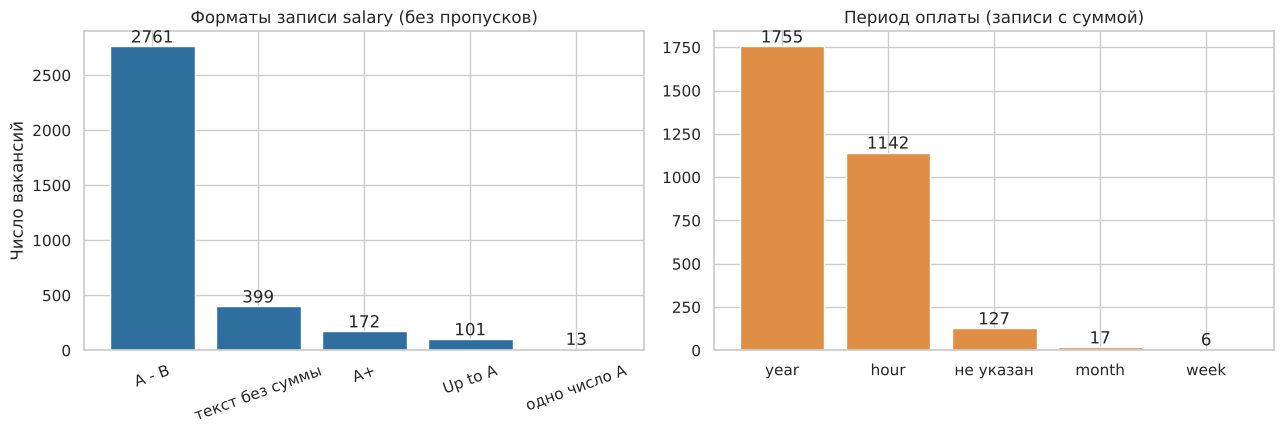

In [10]:
sal = df["salary"].str.replace("\xa0", " ", regex=False).str.strip()

NUM = r"\d[\d,]*(?:\.\d+)?"
# Одно выражение на все числовые форматы. Необязательные части: «Up to», $, «+», второе число, период, «хвост»
SALARY_RE = rf"""^\s*(?P<upto>up\s+to\s+)?\$?\s*(?P<min>{NUM})(?!\w)
                 (?:\s*(?P<plus>\+)|\s*-\s*\$?\s*(?P<max>{NUM})(?!\w))?\s*(?P<dollar>\$)?\s*
                 (?:/\s*(?P<period>hour|year|month|week))?(?P<tail>.*)$"""
ext = sal.str.extract(re.compile(SALARY_RE, re.I | re.X | re.S))

# Перечень встречающихся шаблонов: числа заменены на N, хвост после периода отброшен
template = (sal.str.replace(NUM, "N", regex=True)
               .str.replace(r"(/\s*(?:hour|year|month|week)).*$", r"\1", regex=True, case=False))
print("Самые частые шаблоны записи:")
display(template.value_counts().head(15).rename("число строк").to_frame())

has_num = ext["min"].notna()
fmt = np.select(
    [sal.isna(), ~has_num, ext["upto"].notna(), ext["plus"].notna(), ext["max"].notna()],
    ["пропуск", "текст без суммы", "Up to A", "A+", "A - B"],
    default="одно число A")
fmt = pd.Series(fmt, index=df.index)

has_dollar = sal.str.contains("$", regex=False, na=False)
has_tail = ext["tail"].fillna("").str.strip().ne("")
print("Записей с суммой:", int(has_num.sum()), "| со знаком $:", int((has_dollar & has_num).sum()),
      "| без $:", int((~has_dollar & has_num).sum()), "| с текстовым хвостом после суммы:", int((has_tail & has_num).sum()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
c = fmt[fmt != "пропуск"].value_counts()
axes[0].bar(c.index, c.values, color="#2f6f9f")
for x, v in enumerate(c.values): axes[0].text(x, v, str(v), ha="center", va="bottom")
axes[0].set_title("Форматы записи salary (без пропусков)"); axes[0].set_ylabel("Число вакансий")
axes[0].tick_params(axis="x", rotation=20)

p = ext.loc[has_num, "period"].str.lower().fillna("не указан").value_counts()
axes[1].bar(p.index, p.values, color="#e08e45")
for x, v in enumerate(p.values): axes[1].text(x, v, str(v), ha="center", va="bottom")
axes[1].set_title("Период оплаты (записи с суммой)")
plt.tight_layout(); plt.show()

**Вывод по заданию 2.1.**
- Заполнен `salary` у 3 446 вакансий (15,7%). У 3 047 есть число, у 399 — только текст без суммы (`DOE`, `Competitive`, `Commensurate with Experience`).
- Форматы среди записей с суммой: `A - B` — 2 761 (90,6%), `A+` — 172, `Up to A` — 101, одно число — 13. Наиболее частые шаблоны: `N - N $ /year` (1 641) и `N - N $ /hour` (1 032).
- Знак `$` есть у 2 958 записей, у 89 его нет; у 413 записей после суммы/периода приклеен текстовый «хвост» (`/yearBonus, Benefits`).
- Период указан в большинстве записей: `year` — 1 755, `hour` — 1 142, `month` — 17, `week` — 6; у **127 записей период не указан**.
- Одно регулярное выражение с необязательными частями (`Up to`, `$`, `+`, второе число, период, «хвост») покрывает все числовые форматы, а нечисловые отсеиваются как «текст без суммы».

#### Задание 2.2

1. Разделите столбец `salary` зарплаты три: `минимальная граница зарплаты`, `максимальная граница зарплаты`, `период`. Если значение суммы указано только одно, считайте, что это минимальная зарплата. Значение суммы в обоих столбцах преобразуйте в формат `float`.
2. Покажите на столбчатой диаграмме с группировкой среднюю и медианную минимальную зарплату в каждом периоде. Сделайте выводы.

,salary,salary_min,salary_max,salary_period
12691,18.00 - 25.00 $ /hour,18.0,25.0,hour
10683,30.00 - 43.00 $ /hour,30.0,43.0,hour
20424,"37,440.00 - 47,840.00 $ /year",37440.0,47840.0,year
12405,"50,000.00 - 70,000.00 $ /year",50000.0,70000.0,year
20526,"80,000.00 - 100,000.00 $ /year",80000.0,100000.0,year
12848,0.00 - 35.00 $ /hour,0.0,35.0,hour
1425,26.00 - 32.00 $ /hour,26.0,32.0,hour
7259,"100,000.00 - 110,000.00 $ /year",100000.0,110000.0,year


,count,mean,median
salary_period,,,
hour,1142,187.61,15.13
week,6,593.67,600.00
month,17,6048.41,4905.22
year,1755,59789.88,55000.00


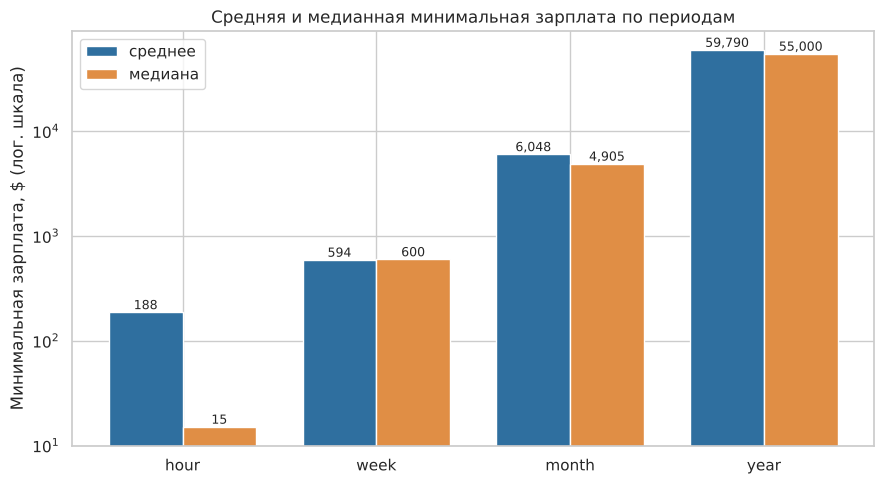

In [11]:
def to_float(s):
    return s.str.replace(",", "", regex=False).astype(float)

df["salary_min"] = to_float(ext["min"])          # единственное число считаем минимальной зарплатой
df["salary_max"] = to_float(ext["max"])
df["salary_period"] = ext["period"].str.lower()
df["salary_format"] = fmt

display(df.loc[has_num, ["salary", "salary_min", "salary_max", "salary_period"]].sample(8, random_state=2))

stats = (df.groupby("salary_period")["salary_min"].agg(["count", "mean", "median"]).round(2)
           .reindex(["hour", "week", "month", "year"]))
display(stats)

# Столбчатая диаграмма с группировкой: среднее и медиана минимальной зарплаты по периодам
x = np.arange(len(stats)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - w/2, stats["mean"], w, label="среднее", color="#2f6f9f")
b2 = ax.bar(x + w/2, stats["median"], w, label="медиана", color="#e08e45")
ax.set_yscale("log")                      # периоды различаются на порядки -> логарифмическая шкала
ax.set_xticks(x); ax.set_xticklabels(stats.index)
for bars in (b1, b2):
    for r in bars:
        ax.text(r.get_x() + r.get_width()/2, r.get_height(), f"{r.get_height():,.0f}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Минимальная зарплата, $ (лог. шкала)")
ax.set_title("Средняя и медианная минимальная зарплата по периодам")
ax.legend(); plt.tight_layout(); plt.show()

**Вывод по заданию 2.2.** Столбцы `salary_min`, `salary_max`, `salary_period` созданы (числа — `float`; единственное число записано в `salary_min`, как требует задание. Замечание: для `Up to A` смысл — «до A», то есть максимум, но по условию такие значения считаем минимумом; формат сохранён в `salary_format`).

| Период | n | Среднее | Медиана |
|---|---|---|---|
| hour | 1 142 | 187,61 | 15,13 |
| week | 6 | 593,67 | 600,00 |
| month | 17 | 6 048,41 | 4 905,22 |
| year | 1 755 | 59 789,88 | 55 000,00 |

Выводы: (1) суммы за разные периоды различаются на порядки (поэтому ось логарифмическая), сравнивать их без приведения к одному периоду нельзя; (2) у `hour` среднее (188) в 12 раз больше медианы (15) — из-за выбросов: есть записи вроде `100 000 $/hour`, по-видимому, годовые суммы с ошибочно указанным периодом, и нулевые минимумы (`0.00 - 35.00`); поэтому медиана здесь надёжнее; (3) для `week` и `month` наблюдений слишком мало (6 и 17), выводам по ним доверять нельзя.

#### Задание 2.3

Как было отмечено в задании 2.1, период, за который указывается зарплата, может отсутствовать. Восполните этот пробел в данных следующим образом:

1. Определите диапазон изменения (разброс) значений денежной суммы за каждый из встречающихся в данных периодов. Постройте гистограмму для каждого периода. Сопоставьте результаты с результатами в задании 2.2.
2. Определите, к среднему значению за какой период ближе всего сумма, у которой период не указан. Укажите для найденный период. В спорных случаях, где сумма одинаково близка к нескольким диапазонам, не выбирайте ничего. Учтите, что в данных могут быть выбросы.

,count,mean,std,min,25%,50%,75%,max
salary_period,,,,,,,,
hour,1142.0,187.61,3575.22,0.0,12.0,15.13,23.0,100000.00
week,6.0,593.67,419.05,12.0,337.5,600.00,900.0,1100.00
month,17.0,6048.41,4607.15,1800.0,3674.0,4905.22,6000.0,17688.94
year,1755.0,59789.88,52169.88,0.0,40000.0,55000.00,75000.0,1000000.00


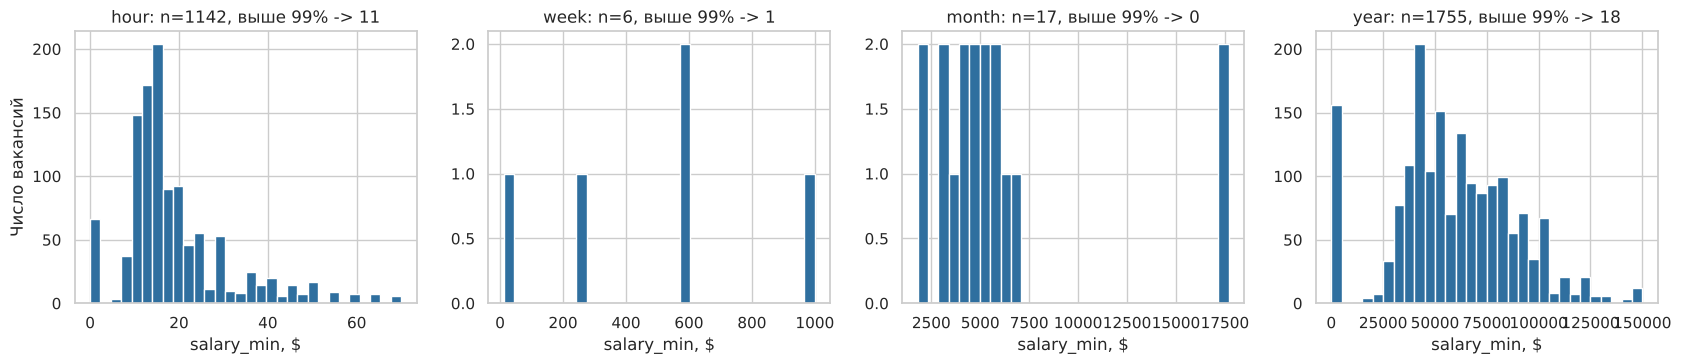

Среднее без выбросов по периодам:
 salary_period
hour        16.16
week       593.67
month     4496.34
year     55691.68



Проверка на известных периодах: решение принято в 92.0% случаев, верно угадано 96.2%

Сумм без периода: 127
  период определён: 115
  спорных, оставлено пустым: 12


,число строк
salary_period_filled,
hour,71
year,41
NaN,12
week,2
month,1


,salary,salary_min,salary_period_filled
5546,Up to $60000.00,60000.0,year
5938,Up to $45000.00,45000.0,year
7742,Up to $14.00,14.0,hour
7505,0.00 - 960.00 $ bi-weeklyPay increase upon completion of training...,0.0,NaN
7908,Up to $20.00,20.0,hour
3165,Up to $150000.00,150000.0,year
2717,Up to $15.00,15.0,hour
21168,Up to $20.00,20.0,hour
5740,Up to $125000.00,125000.0,year
7736,Up to $15.00,15.0,hour


In [12]:
periods = ["hour", "week", "month", "year"]
describe = df.groupby("salary_period")["salary_min"].describe().reindex(periods).round(2)
display(describe)

# 1. Гистограмма для каждого периода (правый «хвост» выше 99-го перцентиля обрезан для читаемости)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, per in zip(axes, periods):
    v = df.loc[df["salary_period"] == per, "salary_min"].dropna()
    cut = v.quantile(0.99)
    ax.hist(v[v <= cut], bins=30, color="#2f6f9f")
    ax.set_title(f"{per}: n={len(v)}, выше 99% -> {int((v > cut).sum())}")
    ax.set_xlabel("salary_min, $")
axes[0].set_ylabel("Число вакансий")
plt.tight_layout(); plt.show()

# 2. Период для сумм, у которых он не указан
def trimmed_mean(s):
    """Среднее без выбросов (правило 1.5·IQR)"""
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return s[(s >= q1 - 1.5 * iqr) & (s <= q3 + 1.5 * iqr)].mean()

centers = df.groupby("salary_period")["salary_min"].apply(trimmed_mean).reindex(periods)
print("Среднее без выбросов по периодам:\n", centers.round(2).to_string())

def guess_period(v, tie_ratio=1.2):
    """Ближайший по среднему период; если 2-й по близости почти так же близок (d2 < 1.2·d1) — не выбираем"""
    if pd.isna(v) or v <= 0:
        return np.nan
    d = (centers - v).abs().sort_values()
    return d.index[0] if d.iloc[1] >= tie_ratio * d.iloc[0] else np.nan

# проверка правила на строках, где период известен
known = df[df["salary_period"].notna()]
pred = known["salary_min"].map(guess_period)
decided = pred.notna()
print(f"\nПроверка на известных периодах: решение принято в {decided.mean():.1%} случаев, "
      f"верно угадано {(pred[decided] == known.loc[decided, 'salary_period']).mean():.1%}")

no_period = df["salary_min"].notna() & df["salary_period"].isna()
df["salary_period_filled"] = df["salary_period"]
df.loc[no_period, "salary_period_filled"] = df.loc[no_period, "salary_min"].map(guess_period)
print("\nСумм без периода:", int(no_period.sum()))
print("  период определён:", int(df.loc[no_period, "salary_period_filled"].notna().sum()))
print("  спорных, оставлено пустым:", int(df.loc[no_period, "salary_period_filled"].isna().sum()))
display(df.loc[no_period, "salary_period_filled"].value_counts(dropna=False).rename("число строк").to_frame())
display(df.loc[no_period, ["salary", "salary_min", "salary_period_filled"]].sample(10, random_state=5))

**Вывод по заданию 2.3.**
- Разброс (см. таблицу и гистограммы): `hour` — основная масса 12–23 $, `week` — 338–900 $, `month` — 3 674–6 000 $, `year` — 40 000–75 000 $. Диапазоны почти не пересекаются, что и позволяет угадывать период по величине суммы. Но в 2.2 среднее по `hour` было раздуто выбросами (188 против 16 без выбросов), поэтому для сравнения использованы **средние без выбросов (правило 1,5·IQR)**: hour — 16,16; week — 593,67; month — 4 496,34; year — 55 691,68.
- Правило: период — тот, к среднему которого сумма ближе всего (по модулю разности); если второй по близости период почти так же близок (расстояние меньше чем в 1,2 раза больше), в спорном случае не выбираем ничего.
- **Проверка правила** на записях, где период известен: решение принимается в 92,0% случаев и в 96,2% из них совпадает с настоящим периодом — правило работает.
- Из 127 сумм без периода период определён у 115 (`hour` — 71, `year` — 41, `week` — 2, `month` — 1), 12 спорных оставлены пустыми (в том числе сумма `0.00`, у которой выбрать период нельзя). Результат записан в `salary_period_filled`; исходный `salary_period` не тронут.

### Задание 3

В задании 3 необходимо провести обработку столбца `job_type`. Выясните, какие форматы значений есть в столбце `job_type`. Сделайте выводы. При необходимости – стройте графики.

Различных записей в job_type (с учётом пропуска): 40


,число строк
job_type,
Full Time,6757
Full Time Employee,6617
"Full Time, Employee",3360
NaN,1628
Full Time Temporary/Contract/Project,1062
"Full Time, Temporary/Contract/Project",533
"Full Time , Employee",406
Part Time Employee,382
Part Time,329


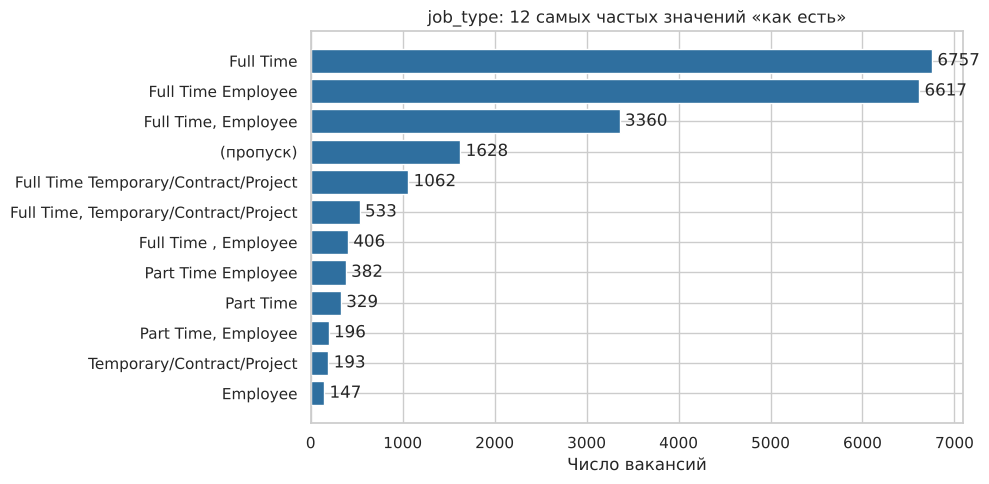

In [13]:
jt_counts = df["job_type"].value_counts(dropna=False)
print("Различных записей в job_type (с учётом пропуска):", len(jt_counts))
display(jt_counts.rename("число строк").to_frame())

top = jt_counts.head(12)[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
labels = ["(пропуск)" if pd.isna(i) else str(i) for i in top.index]
ax.barh(labels, top.values, color="#2f6f9f")
for y, v in enumerate(top.values): ax.text(v, y, f" {v}", va="center")
ax.set_title("job_type: 12 самых частых значений «как есть»"); ax.set_xlabel("Число вакансий")
plt.tight_layout(); plt.show()

**Вывод по первому осмотру `job_type`.** В столбце 39 разных написаний и 1 628 пропусков (7,4%). По сути вариантов гораздо меньше: одна и та же запись `Full Time, Employee` встречается как `Full Time Employee` (6 617), `Full Time, Employee` (3 360), `Full Time , Employee` (406), `Full Time / Employee` (121), `Job Type Full Time Employee` (19), с лишним пробелом и т. д. Различаются разделители, пробелы, префикс `Job Type`, порядок слов не меняется. Кроме `Employee` и `Intern` встречаются `Temporary/Contract/Project` и `Seasonal`, а значение `Exempt` вообще не относится к виду занятости.

Вы заметили, что многие значения фактически одинаковые, но немного по-разному отформатированы? Приведем их к единому формату.

In [14]:
TCP = "Temporary/Contract/Project"
t = df["job_type"].str.replace("\xa0", " ", regex=False)
t = t.str.replace(r"^\s*Job Type\s+", "", regex=True)                  # префикс «Job Type »
t = t.str.replace(TCP, "TCP", regex=False)                               # защищаем «/» внутри значения
t = t.str.replace(r"[,/>]", " ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()
t = t.str.replace(r"^(Full Time|Part Time|Per Diem) (?=\S)", r"\1, ", regex=True)  # единый разделитель «, »
df["job_type_norm"] = t.str.replace("TCP", TCP, regex=False)

print("Было вариантов:", df["job_type"].nunique(), "-> стало:", df["job_type_norm"].nunique())
display(df["job_type_norm"].value_counts(dropna=False).rename("число строк").to_frame())

Было вариантов: 39 -> стало: 15


,число строк
job_type_norm,
"Full Time, Employee",10538
Full Time,6773
"Full Time, Temporary/Contract/Project",1654
NaN,1628
"Part Time, Employee",586
Part Time,330
Temporary/Contract/Project,193
Employee,148
"Part Time, Temporary/Contract/Project",57


**Результат нормализации:** 39 написаний сведены к 15 (14 осмысленных комбинаций + одно «лишнее» `Exempt`). Принцип: убираем префикс `Job Type`, неразрывные и двойные пробелы, заменяем все разделители на единый `, ` между полнотой и типом (внутреннюю косую в `Temporary/Contract/Project` защищаем от замены).

Столбец `job_type` состоит из двух частей: "полнота" занятости (`Full Time`, `Part Time`, `Per Diem`) и "тип" занятости (`Employee`, `Intern`). Кроме того, встречаются и неполные записи.

Задание:
1. Написать одно или несколько регулярных выражений для разделения столбца `job_type` на два: `полнота занятости`, `тип занятости`.
2. Если данные о полноте отсутствуют, внесите значение `Full Time`.
Если отсутствуют данные о типе – внесите `Employee`.
3. Постройте столбчатую диаграмму со стековой группировкой для полноты и типа занятости. Сделайте выводы.

Пропусков до заполнения: полнота = 1970 | тип = 8754
Строки, где не нашли ни одной части (кроме пропусков job_type):


,count
job_type,
Exempt,1


job_kind,Employee,Intern,Seasonal,Temporary/Contract/Project
job_fullness,,,,
Full Time,19088,5,0,1847
Part Time,916,3,17,57
Per Diem,63,0,0,4


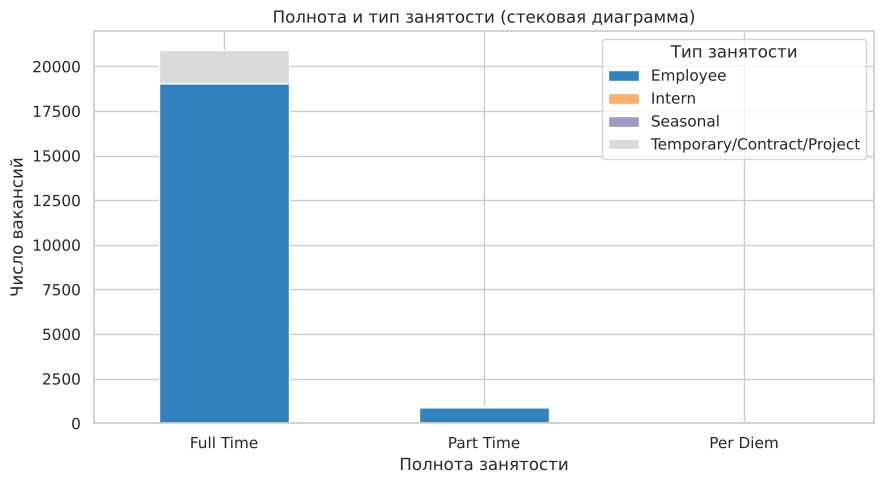

Доля Full Time + Employee: 86.8%
Доля строк, где значение достроено по умолчанию: 41.3%


In [15]:
FULLNESS_RE = r"(Full Time|Part Time|Per Diem)"
KIND_RE = r"(Employee|Intern|Temporary/Contract/Project|Seasonal)"

df["job_fullness"] = df["job_type_norm"].str.extract(FULLNESS_RE)[0]
df["job_kind"] = df["job_type_norm"].str.extract(KIND_RE)[0]

print("Пропусков до заполнения: полнота =", df["job_fullness"].isna().sum(), "| тип =", df["job_kind"].isna().sum())
print("Строки, где не нашли ни одной части (кроме пропусков job_type):")
display(df.loc[df["job_type"].notna() & df["job_fullness"].isna() & df["job_kind"].isna(), "job_type"].value_counts().to_frame())

df["job_type_imputed"] = df["job_fullness"].isna() | df["job_kind"].isna()      # пометим, где значение «достроено»
df["job_fullness"] = df["job_fullness"].fillna("Full Time")
df["job_kind"] = df["job_kind"].fillna("Employee")

ct = pd.crosstab(df["job_fullness"], df["job_kind"])
display(ct)

ax = ct.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="tab20c", rot=0)
ax.set_title("Полнота и тип занятости (стековая диаграмма)")
ax.set_xlabel("Полнота занятости"); ax.set_ylabel("Число вакансий")
ax.legend(title="Тип занятости")
plt.tight_layout(); plt.show()
print("Доля Full Time + Employee: {:.1%}".format(((df["job_fullness"] == "Full Time") & (df["job_kind"] == "Employee")).mean()))
print("Доля строк, где значение достроено по умолчанию:", "{:.1%}".format(df["job_type_imputed"].mean()))

**Вывод по заданию 3.**
- Полнота занятости: `Full Time` — 20 940 (95,2%), `Part Time` — 993 (4,5%), `Per Diem` — 67. Тип занятости: `Employee` — 20 067 (91,2%), `Temporary/Contract/Project` — 1 908 (8,7%), `Seasonal` — 17, `Intern` — 8.
- Доминирует комбинация `Full Time` + `Employee`: 19 088 вакансий (**86,8%**). Постоянная работа на неполный день — 916, временная/контрактная на полный день — 1 847.
- Осторожно: у **41,3%** строк хотя бы одна часть не была указана и достроена по умолчанию (`Full Time`/`Employee`) — 1 628 пропусков `job_type` плюс записи вроде `Employee` или `Temporary/Contract/Project` без второй части. Поэтому доля `Full Time` + `Employee` завышена; для таких строк создан флаг `job_type_imputed`, по которому достроенные значения можно отделить. Единственная запись `Exempt` не содержит ни одной из частей, обе заполнены по умолчанию.

**Итог по датасету.** Добавленные столбцы: `city`, `state`, `zip`, `location_format` (задание 1); `salary_min`, `salary_max`, `salary_period`, `salary_period_filled`, `salary_format` (задание 2); `job_type_norm`, `job_fullness`, `job_kind`, `job_type_imputed` (задание 3). Исходные столбцы не изменялись.

# Порядок защиты работы

**Для защиты работы необходимо:**
1. Предоставить результаты выполнения всех заданий в виде ссылки на Google Colab в новой ветке своего репозитория по первой лабораторной на GitHub. Открыть `pull request`.
2. Выполнить дополнительное задание в процессе сдачи работы. Дополнительное задание представляет собой решение задачи на обработку данных лабораторной работы, меньшее по объему, но сопоставимое по сложности тем заданиям, которые требовалось выполнить в рамках работы.

**Примеры дополнительных заданий:**
1. В столбце `sector` часто представлены данные из столбца `organization` и наоборот. Устраните эту проблему.
2. В столбце `job_title` часто можно частично или полностью встретить указание местоположения организации. Сравните, совпадают ли в таких случаях данные с тем, что указано в столбцах `город`, `код штата`, `почтовый индекс`. Если в этих трех столбцах данные отсутствуют, заполните их данными из столбца `job_title`.
3. Практически во всех столбцах датасета вместо соответствующих названию данных иногда встречается текст из `job_description`. Найдите такие столбцы и записи с описанием вакансии в них. Покажите на столбчатой диаграмме, в каких столбцах и в каком количестве находится информация из столбца `job_description`.

# Дополнительные материалы

1. DAMA-DMBOK: Свод знаний по управлению данными: Второе издание / DAMA International; [пер. с англ.]. – Москва: ООО "Олимп-Бизнес", 2021. – 828 с.
2. Макгрегор, С. Обработка данных на Python: Data Wrangling и Data Quality: [Текст] / С. Макгрегор. – Москва: БХВ, 2024. – 432 с.